# MJO V-JEPA — inference & results

End-to-end: **import data → import the trained model → run inference (one embedding per
day) → save results → infer MJO phases → plot**.  This reuses the project modules
(`jepa.data.dataset`, `jepa.models.encoder`, `jepa.downstream.cluster`) so the inference
path is identical to `jepa.downstream.extract` / `cluster`.

We load **`runs/vjepa/last.tar`** = the *final* EMA target encoder (epoch 99).  We do **not**
use `best.tar`: for latent-space JEPA the val prediction loss bottoms out very early
(~epoch 3, undertrained) because the target hardens as the EMA encoder enriches, so
min-val-loss selects the worst encoder.  `last.tar` roughly doubles the phase–RMM
agreement and adds ~0.09 propagation accuracy.

In [1]:
from datetime import datetime
import os
import netCDF4
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as pcolors
from matplotlib.colors import ListedColormap
import matplotlib.colors as mcolors
import cmaps
%matplotlib inline

def draw(data, mask=None):
    plt.imshow(np.squeeze(data), interpolation='none', cmap=cmaps.cmocean_haline)
    if mask is not None:
        plt.contour(mask, levels=[0.5], colors='k', linewidths=1)
    plt.colorbar()
    plt.show()

## 0. Imports & config

In [2]:
import os, sys, time, yaml
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader

ROOT = "/glade/campaign/univ/uchi0018/weidong/SSL_project/Self_supervised_learning/MJO"
sys.path.insert(0, ROOT)
os.chdir(ROOT)

from jepa.data.dataset import MJOSequence
from jepa.models.encoder import build_encoder
from jepa.downstream.cluster import SOM1D, order_by_convection, circular_accuracy
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

CKPT   = os.path.join(ROOT, "runs/vjepa/last.tar")   # final EMA encoder (not best.tar)
OUT    = os.path.join(ROOT, "runs/vjepa")
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE, "| torch", torch.__version__)
print("ckpt  :", CKPT)

/glade/work/weidong/conda-envs/myenv/lib/python3.10/site-packages/pyramid/path.py:3: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


device: cuda | torch 2.9.0+cu128
ckpt  : /glade/campaign/univ/uchi0018/weidong/SSL_project/Self_supervised_learning/MJO/runs/vjepa/last.tar


In [3]:
with open(os.path.join(ROOT, "jepa/config_vjepa.yaml")) as f:
    cfg = yaml.safe_load(f)
d = cfg["data"]
stats = np.load(os.path.join(d["cache_dir"], "stats.npz"))
lat, lon = stats["lat"], stats["lon"]
print(f"grid: {lat.size} lat x {lon.size} lon  ({lat[0]:.1f}..{lat[-1]:.1f}N, "
      f"{lon[0]:.1f}..{lon[-1]:.1f}E)")
print("variables   :", list(stats["variables"]))
print("train mean  :", np.round(stats["mean"], 2))
print("train std   :", np.round(stats["std"], 2))

grid: 13 lat x 144 lon  (15.0..-15.0N, 0.0..357.5E)
variables   : [np.str_('olr'), np.str_('u850'), np.str_('u200')]
train mean  : [-0.02  0.   -0.01]
train std   : [29.57  3.47  7.41]


## 1. Import data

`MJOSequence` memory-maps the standardized anomaly cache `data/anom_st/anom.npy`
(`[N, C=3, 13, 144]`, channels OLR/U850/U200) and yields 3-day clips
`x = (C, T=3, 13, 144)` with the anchor day `t` last.  No data is held in RAM — only the
memmap and the clip indices.

In [4]:
years = list(range(d["year_start"], d["year_end"] + 1))
ds = MJOSequence(d["cache_dir"], years, seq_len=d["seq_len"])
dl = DataLoader(ds, batch_size=256, shuffle=False, num_workers=4)
dates = ds.anchor_dates().astype("datetime64[D]")

print(f"{len(ds)} daily clips   {dates[0]} -> {dates[-1]}")
sample = ds[0]["x"]
print("one clip tensor (C,T,H,W):", tuple(sample.shape),
      "  value range [%.2f, %.2f]" % (float(sample.min()), float(sample.max())))

15220 daily clips   1979-05-02 -> 2020-12-31
one clip tensor (C,T,H,W): (3, 3, 13, 144)   value range [-5.40, 2.99]


## 2. Import model

The checkpoint stores both the full `VJEPA` (`model`) and the **EMA target encoder**
(`probe_encoder`) saved for downstream use.  Inference uses the EMA target encoder, built
from the saved `config.encoder` and loaded with `build_encoder` — exactly what
`jepa.downstream.extract` does.

In [5]:
ck  = torch.load(CKPT, map_location=DEVICE, weights_only=False)
enc = build_encoder(ck["config"]["encoder"]).to(DEVICE).eval()
enc.load_state_dict(ck["probe_encoder"])

nparam = sum(p.numel() for p in enc.parameters())
print(f"loaded epoch {ck['epoch']}  step {ck['step']}")
print(f"{nparam/1e6:.2f}M params  |  {enc.num_frames} frames  |  embed_dim {ck['config']['encoder']['embed_dim']}")

loaded epoch 246  step 14079
2.81M params  |  3 frames  |  embed_dim 192


## 3. Inference — one embedding per day

For each clip `[t-2, t-1, t]` run the EMA encoder and **mean-pool the current-day (frame
t) tokens** → a single vector for day `t` in the context of its recent evolution.
`frame_token_index(num_frames-1)` selects the day-t tokens.

In [6]:
cur_idx = torch.from_numpy(enc.frame_token_index(enc.num_frames - 1)).long().to(DEVICE)

t0 = time.time(); embs = []
with torch.no_grad():
    for batch in dl:
        x = batch["x"].to(DEVICE, non_blocking=True)
        tokens = enc(x)                    # [B, L, D]
        emb = tokens[:, cur_idx].mean(1)   # current-day token pool -> [B, D]
        embs.append(emb.cpu().numpy())
emb = np.concatenate(embs, 0).astype("float32")
print(f"embeddings {emb.shape}  in {time.time()-t0:.1f}s on {DEVICE}")

embeddings (15220, 192)  in 17.1s on cuda


In [20]:
cur_idx.shape, len(dl), tokens.shape

(torch.Size([234]), 60, torch.Size([116, 702, 192]))

In [26]:
tokens.device

device(type='cuda', index=0)

In [19]:
batch['x'].shape

torch.Size([116, 3, 3, 13, 144])

In [12]:
tokens.shape, emb.shape

(torch.Size([116, 702, 192]), (15220, 192))

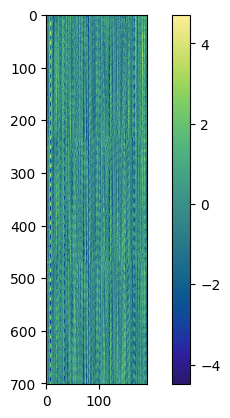

In [8]:
draw(tokens.cpu()[0])


## 4. Save inference results

In [7]:
np.save(os.path.join(OUT, "embeddings.npy"), emb)
np.save(os.path.join(OUT, "emb_dates.npy"), dates)
print("saved:")
print("  ", os.path.join(OUT, "embeddings.npy"), emb.shape)
print("  ", os.path.join(OUT, "emb_dates.npy"), dates.shape)

saved:
   /glade/campaign/univ/uchi0018/weidong/SSL_project/Self_supervised_learning/MJO/runs/vjepa/embeddings.npy (15220, 192)
   /glade/campaign/univ/uchi0018/weidong/SSL_project/Self_supervised_learning/MJO/runs/vjepa/emb_dates.npy (15220,)


## 5. Infer MJO phases (k-means + SOM)

z-score the daily embeddings, cluster into `k=8` phases, then **order clusters eastward**
by the longitude of their composite enhanced-convection centre (min OLR), so phase id
increases like the RMM phases.  Labels are saved to `phase_labels.npz`.

In [24]:
k = 10
Z = (emb - emb.mean(0)) / (emb.std(0) + 1e-6)
lab_km  = KMeans(n_clusters=k, n_init=10, random_state=0).fit(Z).labels_
lab_som = SOM1D(k, iters=30000, seed=0).fit(Z).predict(Z)

# anomaly cache (for eastward ordering + compositing)
anom       = np.load(os.path.join(d["cache_dir"], "anom.npy"), mmap_mode="r")
anom_dates = np.load(os.path.join(d["cache_dir"], "dates.npy")).astype("datetime64[D]")

lab_km,  cen_km,  _ = order_by_convection(lab_km,  k, dates, anom, anom_dates, stats)
lab_som, cen_som, _ = order_by_convection(lab_som, k, dates, anom, anom_dates, stats)

np.savez(os.path.join(OUT, f"phase_{k}_labels.npz"), dates=dates, kmeans=lab_km, som=lab_som)
print("phase counts (kmeans):", np.bincount(lab_km, minlength=k))
print("convection centre lon:", np.round(cen_km).astype(int), "deg E")
print("saved", os.path.join(OUT, f"phase_{k}_labels.npz"))

phase counts (kmeans): [1380 1126 1217 1686 1265 1615 1808 1800 1438 1885]
convection centre lon: [ 58  72  82  95 130 140 150 180 265 312] deg E
saved /glade/campaign/univ/uchi0018/weidong/SSL_project/Self_supervised_learning/MJO/runs/vjepa/phase_10_labels.npz


In [14]:
lab_som.shape, lab_som[::100]

((15220,),
 array([2, 4, 2, 5, 2, 4, 5, 2, 1, 4, 3, 5, 4, 0, 5, 2, 1, 3, 2, 0, 0, 3,
        0, 4, 5, 3, 4, 4, 3, 3, 0, 0, 3, 2, 1, 5, 5, 4, 1, 2, 2, 1, 1, 5,
        0, 4, 5, 5, 4, 1, 5, 5, 4, 0, 2, 0, 1, 3, 5, 1, 4, 3, 5, 4, 4, 3,
        0, 1, 3, 3, 2, 4, 3, 5, 1, 5, 3, 0, 1, 5, 3, 4, 4, 3, 2, 4, 2, 2,
        0, 1, 5, 5, 0, 0, 5, 2, 1, 5, 3, 1, 1, 2, 5, 4, 1, 2, 4, 1, 5, 5,
        0, 4, 2, 5, 1, 4, 3, 5, 1, 2, 2, 1, 4, 2, 3, 4, 4, 3, 2, 1, 2, 5,
        4, 4, 5, 5, 1, 4, 5, 4, 1, 5, 3, 1, 0, 5, 2, 4, 4, 5, 0, 1, 3]))

## 6. Agreement with the classical WH04 RMM phase (active days, amplitude ≥ 1)

In [9]:
rmm = pd.read_csv(d["rmm_csv"], parse_dates=["time"])
rmm["date"] = rmm["time"].values.astype("datetime64[D]")
rb = rmm.set_index("date")
common = np.intersect1d(dates, rb.index.values)
ei     = pd.Index(dates).get_indexer(common)
amp    = rb.loc[common, "amplitude"].values
rphase = rb.loc[common, "phase"].values.astype(int) - 1   # 0..7
active = amp >= 1.0

for name, lab in [("kmeans", lab_km), ("som", lab_som)]:
    c, r = lab[ei][active], rphase[active]
    print(f"{name:7s} ARI={adjusted_rand_score(r,c):.3f}  "
          f"NMI={normalized_mutual_info_score(r,c):.3f}  "
          f"circular_acc={circular_accuracy(c,r,k):.3f}   (n_active={active.sum()})")

kmeans  ARI=0.167  NMI=0.296  circular_acc=0.276   (n_active=9225)
som     ARI=0.176  NMI=0.301  circular_acc=0.293   (n_active=9225)


## 7. Plots

### 7a. Representation health (no collapse)
All embedding dims carry variance and the effective rank is well above 1 — the encoder did
not collapse to a constant.

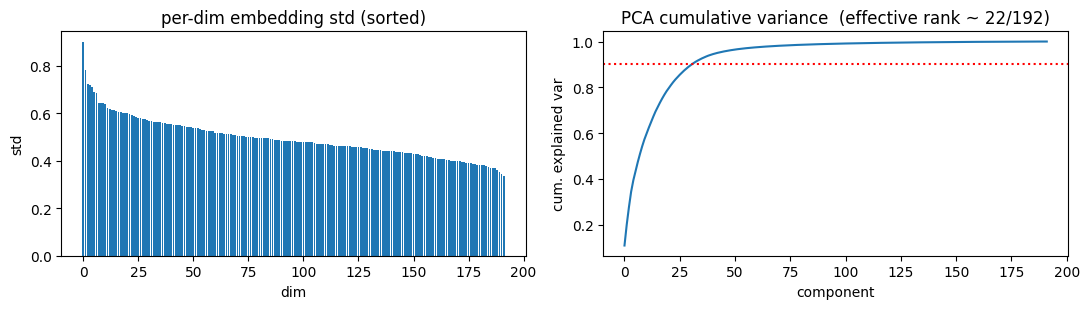

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].bar(range(emb.shape[1]), np.sort(emb.std(0))[::-1])
ax[0].set(title="per-dim embedding std (sorted)", xlabel="dim", ylabel="std")

pca = PCA().fit(Z)
cev = np.cumsum(pca.explained_variance_ratio_)
er  = (pca.explained_variance_.sum()**2) / np.square(pca.explained_variance_).sum()
ax[1].plot(cev); ax[1].axhline(0.9, ls=":", c="r")
ax[1].set(title=f"PCA cumulative variance  (effective rank ~ {er:.0f}/{emb.shape[1]})",
          xlabel="component", ylabel="cum. explained var")
plt.tight_layout(); plt.show()

### 7b. Phase composites — OLR shading (W m$^{-2}$) + U850 contours
The enhanced-convection centre (blue, negative OLR anomaly) should march **eastward** with
phase id across the Indian Ocean → Maritime Continent → West Pacific.

In [12]:
import os, sys, pickle
import matplotlib.pyplot as plt
import numpy as np

FB_ROOT = "/glade/work/weidong/code/FB"
sys.path.insert(0, FB_ROOT)
from evaluation.plot_config import params
plt.rcParams.update(params)

✗ LaTeX not found in PATH
🎨 Scientific plotting configuration loaded
   LaTeX support: ✗ Disabled
   Default save format: png
   Contour levels: 100
   Colormap: bwr


/glade/work/weidong/code/FB/evaluation/plot_config.py:125: UserWarning: LaTeX not found. Falling back to standard matplotlib fonts. For better typography, install LaTeX (see README for instructions).
  warnings.warn(


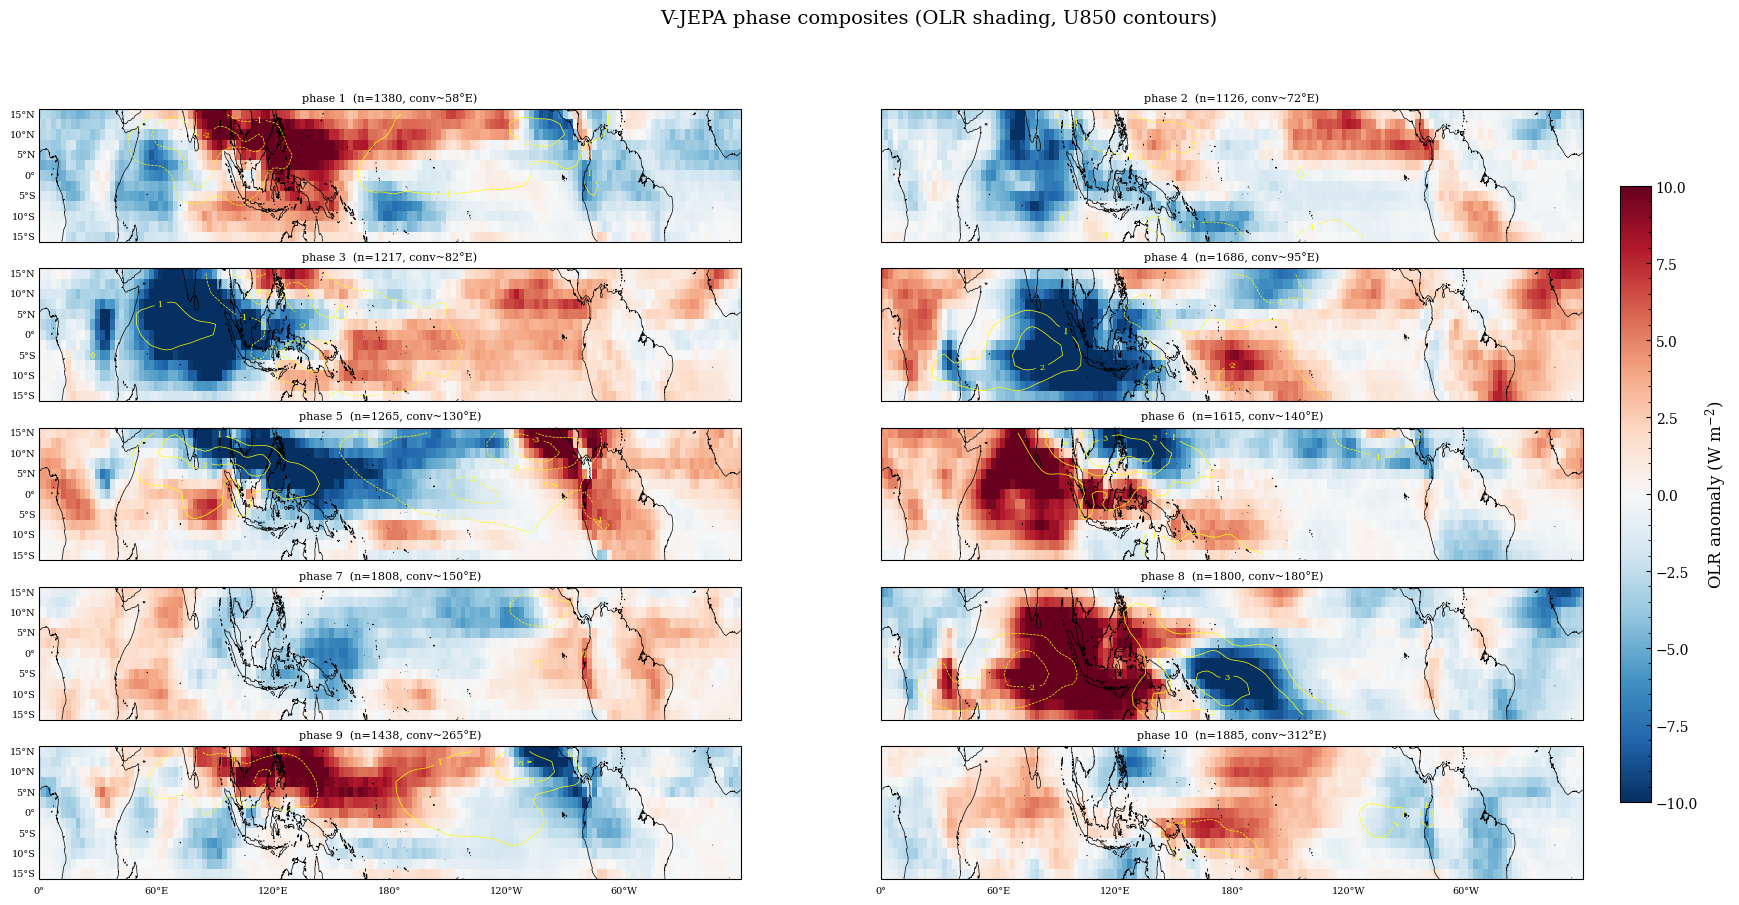

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

# ---- 标准化参数 ----
omean, ostd = float(stats["mean"][0]), float(stats["std"][0])
umean, ustd = float(stats["mean"][1]), float(stats["std"][1])
pos = pd.Index(anom_dates).get_indexer(dates)

# ---- 投影：lon 为 0–360 用 central_longitude=180；-180–180 改成 0 ----
proj = ccrs.PlateCarree(central_longitude=180)
data_crs = ccrs.PlateCarree()

nrow = (k + 1) // 2
# 每行高度从 1.7 提到 2.6，热带条带不再被压扁
fig, axes = plt.subplots(nrow, 2, figsize=(24, 2 * nrow),
                         sharex=True, sharey=True,
                         subplot_kw={"projection": proj})
axflat = axes.ravel()

pm = None
for c, ax in zip(range(k), axflat):
    rows = pos[(lab_km == c) & (pos >= 0)]
    comp_olr = np.asarray(anom[rows, 0]).mean(0) * ostd + omean
    comp_u   = np.asarray(anom[rows, 1]).mean(0) * ustd + umean

    pm = ax.pcolormesh(lon, lat, comp_olr, cmap="RdBu_r",
                       vmin=-10, vmax=10, shading="nearest",
                       transform=data_crs)
    cs = ax.contour(lon, lat, comp_u, levels=[-3, -2, -1, 1, 2, 3],
                    colors="yellow", linewidths=0.5, transform=data_crs)
    ax.clabel(cs, inline=True, fontsize=6, fmt="%.0f")

    ax.coastlines(linewidth=0.5)
    ax.set_aspect("auto")  
    ax.set_title(f"phase {c+1}  (n={rows.size}, conv~{cen_km[c]:.0f}°E)",
                 fontsize=8)

# 多出来的空子图（k 为奇数时）隐藏
for ax in axflat[k:]:
    ax.set_visible(False)

# ---- 经纬度刻度标注 ----
for i, ax in enumerate(axflat[:k]):
    gl = ax.gridlines(draw_labels=True, linewidth=0,
                      x_inline=False, y_inline=False)
    gl.top_labels = gl.right_labels = False
    gl.bottom_labels = (i >= k - 2)        # 仅最后一行显示经度
    gl.left_labels = (i % 2 == 0)          # 仅左列显示纬度
    gl.xlabel_style = {"size": 7}
    gl.ylabel_style = {"size": 7}

# ---- colorbar 与总标题 ----
fig.colorbar(pm, ax=axes, shrink=0.8, pad=0.02,
             label="OLR anomaly (W m$^{-2}$)")
fig.suptitle("V-JEPA phase composites (OLR shading, U850 contours)", y=0.98)
os.makedirs('img', exist_ok=True)
output_file = f'/glade/campaign/univ/uchi0018/weidong/SSL_project/Self_supervised_learning/MJO/jepa/img/V-JEPA_phase_{k}_composites.png'
plt.savefig(output_file, dpi=600, bbox_inches='tight')
# plt.savefig(output_file.replace('.png', '.svg'), format='svg', bbox_inches='tight')
# plt.show()

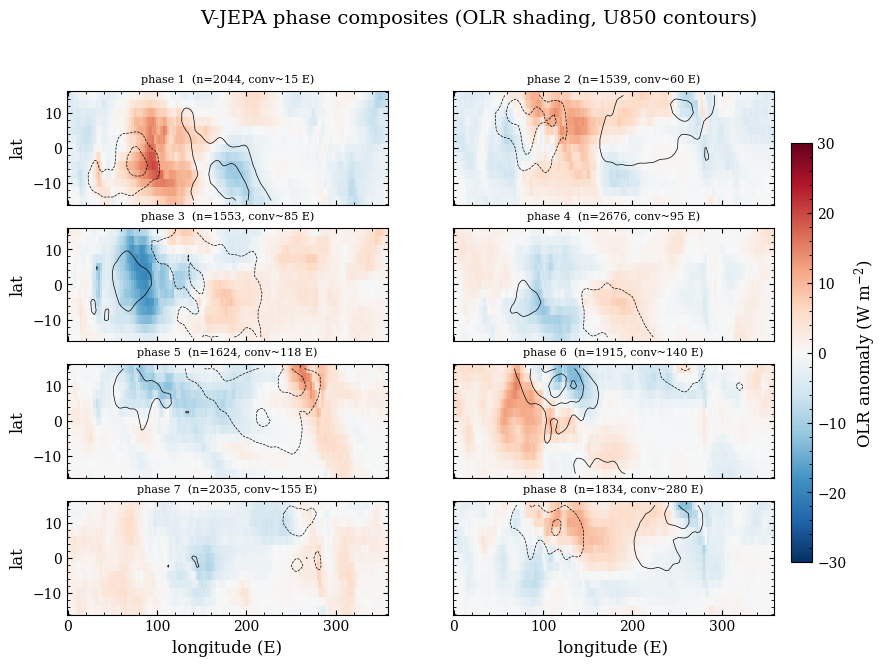

In [20]:
omean, ostd = float(stats["mean"][0]), float(stats["std"][0])
umean, ustd = float(stats["mean"][1]), float(stats["std"][1])
pos = pd.Index(anom_dates).get_indexer(dates)

nrow = (k + 1) // 2
fig, axes = plt.subplots(nrow, 2, figsize=(11, 1.7*nrow), sharex=True, sharey=True)
for c, ax in zip(range(k), axes.ravel()):
    rows = pos[(lab_km == c) & (pos >= 0)]
    comp_olr = np.asarray(anom[rows, 0]).mean(0) * ostd + omean
    comp_u   = np.asarray(anom[rows, 1]).mean(0) * ustd + umean
    pm = ax.pcolormesh(lon, lat, comp_olr, cmap="RdBu_r", vmin=-30, vmax=30, shading="nearest")
    ax.contour(lon, lat, comp_u, levels=[-3,-2,-1,1,2,3], colors="k", linewidths=0.5)
    ax.set_title(f"phase {c+1}  (n={rows.size}, conv~{cen_km[c]:.0f} E)", fontsize=8)
for a in axes[-1]: a.set_xlabel("longitude (E)")
for a in axes[:, 0]: a.set_ylabel("lat")
fig.colorbar(pm, ax=axes, shrink=0.8, pad=0.02, label="OLR anomaly (W m$^{-2}$)")
fig.suptitle("V-JEPA phase composites (OLR shading, U850 contours)", y=1.0)
os.makedirs('img', exist_ok=True)
output_file = 'img/V-JEPA_phase_composites.png'
plt.savefig(output_file, dpi=300, bbox_inches='tight')
plt.savefig(output_file.replace('.png', '.svg'), format='svg', bbox_inches='tight')
# plt.show()

### 7c. Embedding structure & phase correspondence
Left: PCA(1,2) of the daily embeddings coloured by inferred phase — the slow oscillation
traces a ring.  Right: P(V-JEPA phase | RMM phase) on active days; a bright diagonal band
means the unsupervised phases line up with the classical RMM phases.

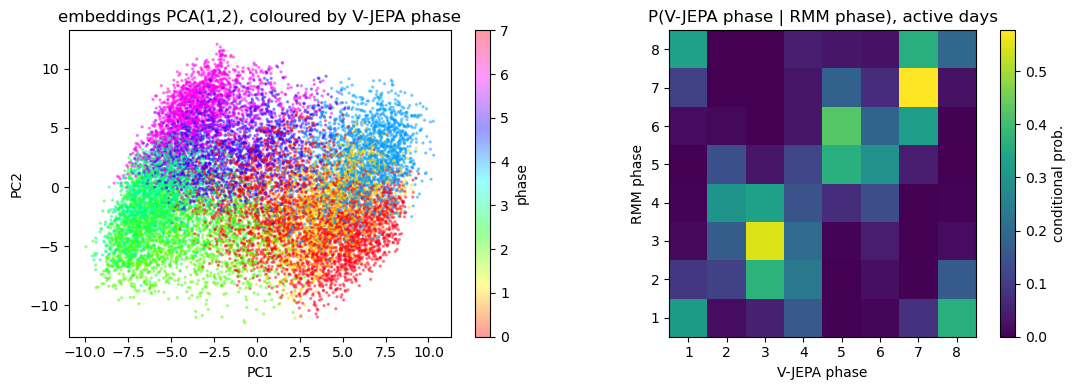

In [11]:
P = pca.transform(Z)[:, :2]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sc = ax[0].scatter(P[:, 0], P[:, 1], c=lab_km, cmap="hsv", s=2, alpha=0.4)
ax[0].set(title="embeddings PCA(1,2), coloured by V-JEPA phase", xlabel="PC1", ylabel="PC2")
plt.colorbar(sc, ax=ax[0], label="phase")

c, r = lab_km[ei][active], rphase[active]
M = np.zeros((k, k))
for rr, cc in zip(r, c): M[rr, cc] += 1
M = M / M.sum(1, keepdims=True)
im = ax[1].imshow(M, cmap="viridis", origin="lower")
ax[1].set(title="P(V-JEPA phase | RMM phase), active days",
          xlabel="V-JEPA phase", ylabel="RMM phase")
ax[1].set_xticks(range(k)); ax[1].set_xticklabels(range(1, k+1))
ax[1].set_yticks(range(k)); ax[1].set_yticklabels(range(1, k+1))
plt.colorbar(im, ax=ax[1], label="conditional prob.")
plt.tight_layout(); plt.show()

### 7d. Temporal coherence
A real MJO phase evolves slowly: from one day to the next it should stay put or move to a
circularly-adjacent phase.  The inferred phases do; randomly-shuffled labels do not.

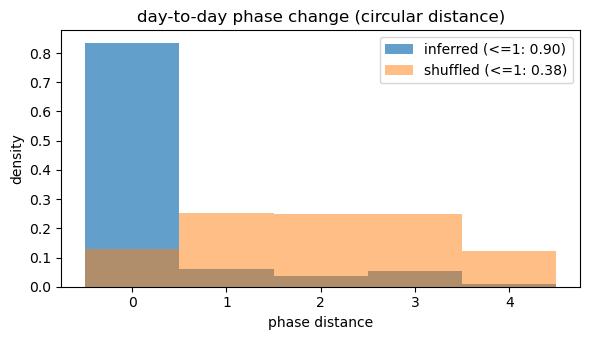

In [12]:
same_day = np.diff(dates).astype("timedelta64[D]").astype(int) == 1
dd   = np.abs(np.diff(lab_km)); circ = np.minimum(dd, k - dd)[same_day]
rng  = np.random.default_rng(0); sh = lab_km.copy(); rng.shuffle(sh)
dds  = np.minimum(np.abs(np.diff(sh)), k - np.abs(np.diff(sh)))[same_day]

fig, ax = plt.subplots(figsize=(6, 3.5))
bins = np.arange(k//2 + 2) - 0.5
ax.hist(circ, bins=bins, density=True, alpha=0.7, label=f"inferred (<=1: {np.mean(circ<=1):.2f})")
ax.hist(dds,  bins=bins, density=True, alpha=0.5, label=f"shuffled (<=1: {np.mean(dds<=1):.2f})")
ax.set(title="day-to-day phase change (circular distance)",
       xlabel="phase distance", ylabel="density"); ax.legend()
plt.tight_layout(); plt.show()

## Summary

- **Data:** standardized WH04 anomaly cache, 3-day clips `(C=3, T=3, 13, 144)`,
  1979–2020, ~15 k days.
- **Model:** EMA target encoder from `runs/vjepa/last.tar` (epoch 99), ~3.16 M params.
- **Inference:** one 192-D embedding per day (current-day token pool).
- **Saved:** `embeddings.npy`, `emb_dates.npy`, `phase_labels.npz` in `runs/vjepa/`.
- **Results:** eastward-marching phase composites, phase–RMM agreement (ARI/NMI/circular
  acc), a low-effective-rank but non-collapsed representation, and slow day-to-day phase
  evolution — all consistent with the MJO.

For the propagation-type head (standing/jumping/slow/fast), run
`python -m jepa.downstream.propagation --ckpt runs/vjepa/last.tar`.